# Exploración reproducible: `phishing_email_detection_50k_copy`

Este notebook lee el CSV original sin modificarlo. El análisis completo se guarda en [`../reports/phishing_email_detection_50k_copy.md`](../reports/phishing_email_detection_50k_copy.md).

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
while not (HERE / 'notebooks' / 'exploracion-datasets' / 'dataset_audit.py').exists():
    if HERE.parent == HERE:
        raise FileNotFoundError('No se encontró la raíz del repositorio')
    HERE = HERE.parent
sys.path.insert(0, str(HERE / 'notebooks' / 'exploracion-datasets'))
from dataset_audit import DATASETS, analyze_dataset, load_dataset, combined_text
spec = next(item for item in DATASETS if item.slug == 'phishing_email_detection_50k_copy')
df = load_dataset(spec)
result = analyze_dataset(spec)
print(f'Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas')
print(f'Objetivo: {spec.target}')

Dimensiones: 50,000 filas × 44 columnas
Objetivo: label


## Esquema, tipos y nulos

In [2]:
schema = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'nulos_pct': (df.isna().mean() * 100).round(2),
})
display(schema)

,tipo,nulos,nulos_pct
email_id,str,0,0.00
sender_name,str,0,0.00
sender_email,str,0,0.00
sender_ip,str,0,0.00
sender_country,str,0,0.00
sender_domain,str,0,0.00
domain_age_days,int64,0,0.00
recipient_email,str,0,0.00
subject,str,0,0.00
email_body,str,0,0.00


## Clases, duplicados y conflictos

,registros
label,
Legitimate,29629
Phishing,20371


Filas duplicadas: 0
Filas con texto repetido: 0
Textos con etiquetas conflictivas: 0


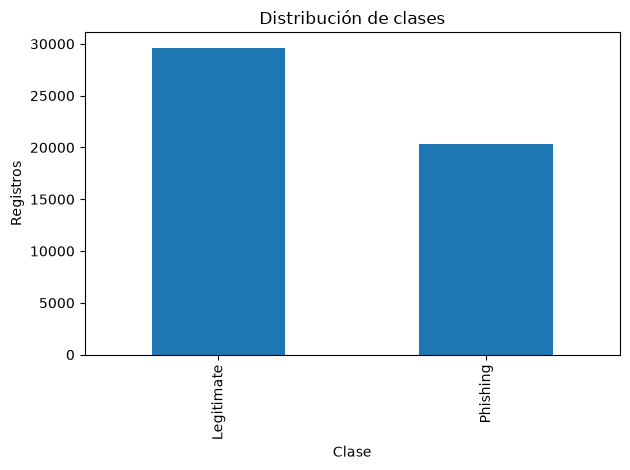

In [3]:
display(df[spec.target].value_counts(dropna=False).rename('registros').to_frame())
print('Filas duplicadas:', result['full_row_duplicates'])
print('Filas con texto repetido:', result['text_duplicates'])
print('Textos con etiquetas conflictivas:', result['conflicting_normalized_texts'])
df[spec.target].astype(str).value_counts().plot(kind='bar', title='Distribución de clases')
plt.xlabel('Clase'); plt.ylabel('Registros'); plt.tight_layout(); plt.show()

## Longitud, idioma y patrones

,caracteres,palabras
count,50000.0000,50000.00000
min,234.0000,32.00000
q25,318.0000,44.00000
median,362.0000,51.00000
mean,362.2145,50.69014
q75,406.0000,57.00000
p95,448.0000,63.00000
max,516.0000,75.00000


Idiomas declarados o estimados: {'English': 50000}
Filas con URL/correo/teléfono: 0 0 0


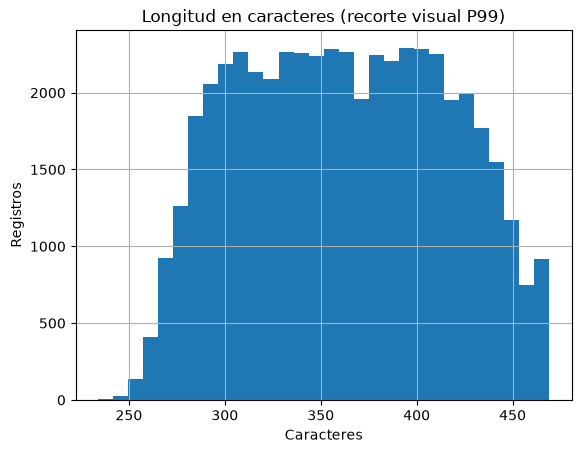

In [4]:
display(pd.DataFrame({
    'caracteres': result['length_characters'],
    'palabras': result['length_words'],
}))
print('Idiomas declarados o estimados:', result['declared_languages'] or result['language_heuristic'])
print('Filas con URL/correo/teléfono:', result['rows_with_url_pattern'], result['rows_with_email_pattern'], result['rows_with_phone_pattern'])
text = combined_text(df, spec.text_columns)
text.str.len().clip(upper=text.str.len().quantile(.99)).hist(bins=30)
plt.title('Longitud en caracteres (recorte visual P99)'); plt.xlabel('Caracteres'); plt.ylabel('Registros'); plt.show()

## Ejemplos sanitizados y conclusión

In [5]:
for label, examples in result['examples'].items():
    print(f'\nClase {label}')
    for example in examples:
        print('-', example)


Clase Legitimate
- Payment Schedule Received Dear User, We're reaching out regarding your recent activity. The requested report has been generated. No additional action is required. Your transaction was completed successfully. Your payment has been received. Your transaction was completed successfu…
- Monthly Report Processed Good Afternoon, Please review the following information. Your transaction was completed successfully. Your transaction was completed successfully. Your meeting invitation has been created. No additional action is required. Your transaction was completed s…

Clase Phishing
- Action Required: Recover Your Security Hi, Your banking information requires verification. Click the secure link below. Claim your reward before it expires. Login now to prevent interruption. Your payment method has expired. Failure to respond may suspend your account. Click the …
- Attention: Confirm Your Identity Dear User, Your mailbox storage is almost full. Your payment method has expired

La interpretación, riesgos de fuga, sesgos, utilidad para Random Forest y estrategia de combinación están documentados en [`../reports/phishing_email_detection_50k_copy.md`](../reports/phishing_email_detection_50k_copy.md).